In [1]:
import pandas as pd
df = pd.read_csv(
    "/content/drive/MyDrive/Project/Amazon-Products.csv"
)
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nNumber of unique main categories:")
print(df["main_category"].nunique())

print("\nProducts in each main category:")
print(df["main_category"].value_counts())

Dataset shape: (551585, 10)

Column names:
['Unnamed: 0', 'name', 'main_category', 'sub_category', 'image', 'link', 'ratings', 'no_of_ratings', 'discount_price', 'actual_price']

Number of unique main categories:
20

Products in each main category:
main_category
accessories                116141
men's clothing              76656
women's clothing            76512
tv, audio & cameras         68659
men's shoes                 57456
appliances                  33096
stores                      32903
home & kitchen              14568
kids' fashion               13488
sports & fitness            12648
bags & luggage              10416
beauty & health             10122
car & motorbike              7080
toys & baby products         6216
women's shoes                5472
industrial supplies          4104
grocery & gourmet foods      3312
pet supplies                 1632
music                        1080
home, kitchen, pets            24
Name: count, dtype: int64


In [2]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nNumber of unique product names:")
print(df["name"].nunique())

print("\nNumber of unique product links:")
print(df["link"].nunique())

Missing values in each column:
Unnamed: 0             0
name                   0
main_category          0
sub_category           0
image                  0
link                   0
ratings           175794
no_of_ratings     175794
discount_price     61163
actual_price       17813
dtype: int64

Number of duplicate rows:
0

Number of unique product names:
396210

Number of unique product links:
551585


In [3]:
TARGET_PRODUCT_COUNT = 10000
MAX_PRODUCTS_PER_CATEGORY = 500
# Select up to 500 products from each category
category_samples = []

for category, group in df.groupby("main_category"):
    sample_size = min(MAX_PRODUCTS_PER_CATEGORY, len(group))

    category_samples.append(
        group.sample(n=sample_size, random_state=42)
    )

# Combine the category samples
category_sample = pd.concat(category_samples)

# Find the remaining products
remaining_products = df.drop(index=category_sample.index)

# Select additional products to reach 10,000
additional_count = TARGET_PRODUCT_COUNT - len(category_sample)

additional_products = remaining_products.sample(
    n=additional_count,
    random_state=42
)

# Combine all selected products
products = pd.concat(
    [category_sample, additional_products],
    ignore_index=True
)

# Shuffle the products
products = products.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Verify the result
print("Original dataset shape:", df.shape)
print("Selected products shape:", products.shape)

display(products.head())

Original dataset shape: (551585, 10)
Selected products shape: (10000, 10)


,Unnamed: 0,name,main_category,sub_category,image,link,ratings,no_of_ratings,discount_price,actual_price
0,462,PEDIGREE Biscrok Biscuits Dog Treats Chicken F...,pet supplies,All Pet Supplies,https://m.media-amazon.com/images/I/61XOAg-Eg9...,https://www.amazon.in/PEDIGREE-Biscrok-Biscuit...,4.5,2,NaN,NaN
1,7849,Jack & Jones Men Jeans,men's clothing,Jeans,https://m.media-amazon.com/images/W/IMAGERENDE...,https://www.amazon.in/Jack-Jones-139437701-Lig...,NaN,NaN,NaN,"₹3,999"
2,674,KN Mall Ladies Curly Hair Machine Curl Secret ...,beauty & health,Personal Care Appliances,https://m.media-amazon.com/images/W/IMAGERENDE...,https://www.amazon.in/KN-Machine-Revolutionary...,NaN,NaN,"₹1,449","₹2,449"
3,6266,Macho Men's Cotton Brief/Underwear Multicolor ...,men's clothing,Innerwear,https://m.media-amazon.com/images/I/712xi+V9Gw...,https://www.amazon.in/Macho-Smart-Cotton-Brief...,4.1,58,₹470,₹699
4,139,"TRASE Unisex Baby & Kids Sandals | Soft, Comfo...",kids' fashion,Kids' Fashion,https://m.media-amazon.com/images/I/71OuDuEQl2...,https://www.amazon.in/TRASE-88-018-Blue-Unisex...,3.9,418,₹359,₹599


In [4]:
print("Missing values in selected products:")
print(products.isnull().sum())

print("\nProducts in each category:")
print(products["main_category"].value_counts())

Missing values in selected products:
Unnamed: 0           0
name                 0
main_category        0
sub_category         0
image                0
link                 0
ratings           2702
no_of_ratings     2702
discount_price    1203
actual_price       268
dtype: int64

Products in each category:
main_category
accessories                594
women's clothing           567
men's clothing             566
tv, audio & cameras        562
men's shoes                561
stores                     530
appliances                 526
bags & luggage             512
sports & fitness           511
home & kitchen             510
kids' fashion              509
car & motorbike            508
grocery & gourmet foods    505
beauty & health            504
toys & baby products       504
women's shoes              504
industrial supplies        502
pet supplies               501
music                      500
home, kitchen, pets         24
Name: count, dtype: int64


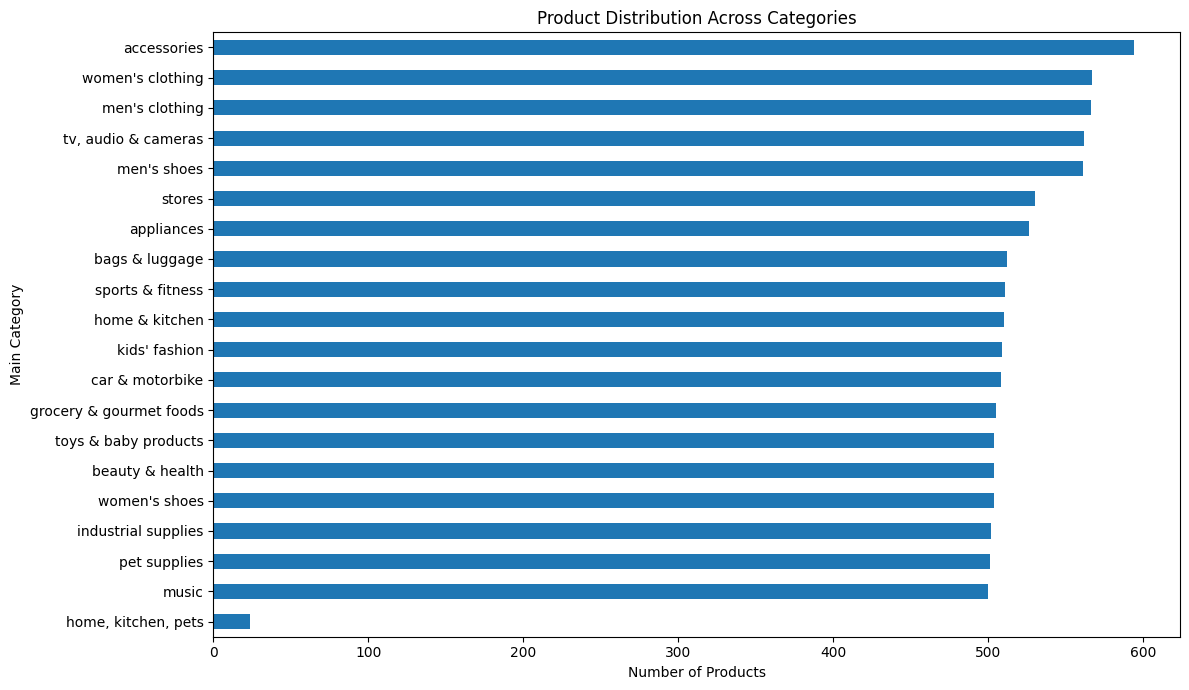

In [5]:
import matplotlib.pyplot as plt

category_counts = products["main_category"].value_counts()

plt.figure(figsize=(12, 7))
category_counts.sort_values().plot(kind="barh")

plt.title("Product Distribution Across Categories")
plt.xlabel("Number of Products")
plt.ylabel("Main Category")

plt.tight_layout()
plt.show()

Products with available ratings: 7130
Average rating: 3.88
Median rating: 4.0
Minimum rating: 1.0
Maximum rating: 5.0


<function matplotlib.pyplot.show(close=None, block=None)>

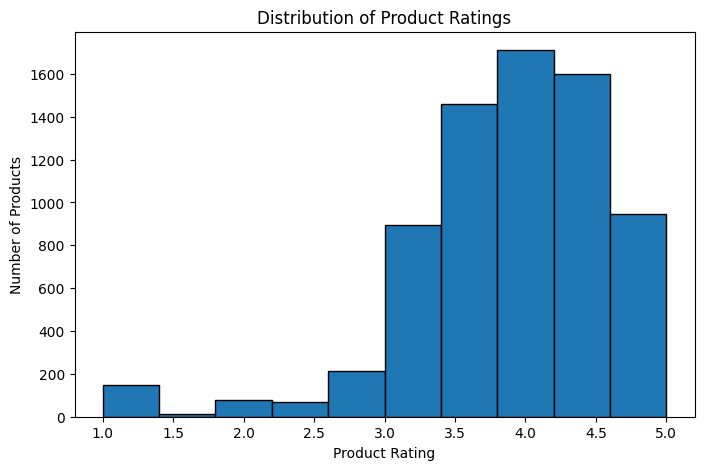

In [6]:
valid_ratings = pd.to_numeric(
    products["ratings"],
    errors="coerce"
).dropna()

print("Products with available ratings:",len(valid_ratings))
print("Average rating:",round(valid_ratings.mean(),2))
print("Median rating:", round(valid_ratings.median(), 2))
print("Minimum rating:", valid_ratings.min())
print("Maximum rating:", valid_ratings.max())

plt.figure(figsize=(8,5))
plt.hist(valid_ratings,bins=10,edgecolor="black")

plt.title("Distribution of Product Ratings")
plt.xlabel("Product Rating")
plt.ylabel("Number of Products")

plt.show

In [7]:
discount_prices = pd.to_numeric(
    products["discount_price"]
    .str.replace("₹", "")
    .str.replace(",", ""),
    errors="coerce"
).dropna()

actual_prices = pd.to_numeric(
    products["actual_price"]
    .str.replace("₹", "")
    .str.replace(",", ""),
    errors="coerce"
).dropna()

print("Discounted price statistics:")
print("Available prices:", len(discount_prices))
print("Average price:", round(discount_prices.mean(), 2))
print("Median price:", round(discount_prices.median(), 2))
print("Minimum price:", discount_prices.min())
print("Maximum price:", discount_prices.max())


print("\nActual price statistics:")
print("Available prices:", len(actual_prices))
print("Average price:", round(actual_prices.mean(), 2))
print("Median price:", round(actual_prices.median(), 2))
print("Minimum price:", actual_prices.min())
print("Maximum price:", actual_prices.max())

Discounted price statistics:
Available prices: 8797
Average price: 2033.84
Median price: 599.0
Minimum price: 20.0
Maximum price: 1249990.0

Actual price statistics:
Available prices: 9732
Average price: 3518.09
Median price: 1249.0
Minimum price: 20.0
Maximum price: 1594900.0


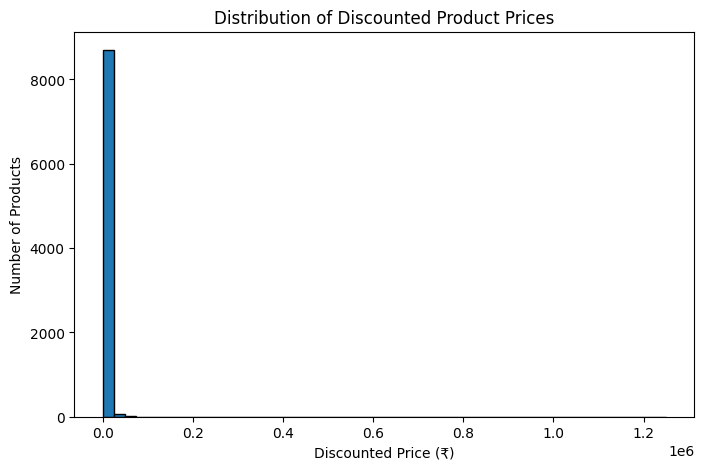

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(discount_prices, bins=50, edgecolor="black")

plt.title("Distribution of Discounted Product Prices")
plt.xlabel("Discounted Price (₹)")
plt.ylabel("Number of Products")

plt.show()

In [9]:
products["product_features"] = (
    products["name"].str.lower() + " " +
    products["main_category"].str.lower() + " " +
    products["sub_category"].str.lower()
)

display(
    products[[
        "name",
        "main_category",
        "sub_category",
        "product_features"
    ]].head()
)

,name,main_category,sub_category,product_features
0,PEDIGREE Biscrok Biscuits Dog Treats Chicken F...,pet supplies,All Pet Supplies,pedigree biscrok biscuits dog treats chicken f...
1,Jack & Jones Men Jeans,men's clothing,Jeans,jack & jones men jeans men's clothing jeans
2,KN Mall Ladies Curly Hair Machine Curl Secret ...,beauty & health,Personal Care Appliances,kn mall ladies curly hair machine curl secret ...
3,Macho Men's Cotton Brief/Underwear Multicolor ...,men's clothing,Innerwear,macho men's cotton brief/underwear multicolor ...
4,"TRASE Unisex Baby & Kids Sandals | Soft, Comfo...",kids' fashion,Kids' Fashion,"trase unisex baby & kids sandals | soft, comfo..."


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(stop_words="english")

tfidf_matrix = tfidf_vectorizer.fit_transform(
    products["product_features"]
)

print("Number of products:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])
print("TF-IDF matrix shape:", tfidf_matrix.shape)

print("\nSample features:")
print(tfidf_vectorizer.get_feature_names_out()[:20])

Number of products: 10000
Number of features: 19346
TF-IDF matrix shape: (10000, 19346)

Sample features:
['00' '000' '0000' '00005' '00007' '0001' '000100' '0005p' '001' '001g'
 '001mm' '001x12' '002' '003' '004' '004grn' '004mar' '005' '0051' '006']
